# Mars Humidity Regression

Goal: predict the humidity reading (`HUMIDITY_Sensor_A`) from the other rover sensors using Linear Regression, Ridge (L2) and Lasso (L1).

**Data:** rover sensor readings as a CSV (about 1 million rows, one reading per second). The notebook asks you to upload it in the next section, so run it in Google Colab.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error

## Load the data

In [3]:
from google.colab import files
up = files.upload()
CSV_PATH = list(up)[0]
print("Using", CSV_PATH)

Saving dataset26.csv to dataset26.csv
Using dataset26.csv


In [4]:
df = pd.read_csv(CSV_PATH)
print(df.shape)
print(df.columns.tolist())
df.head()

(1048575, 9)
['Local_Mean_Solar_Time', 'Local_True_Solar_Time', 'HUMIDITY_Sensor_A', 'HUMIDITY_Sensor_B', 'HUMIDITY_Sensor_TEMPERATURE', 'HUMIDITY_TEMP_UNCERTAINTY', 'THERMOCOUPLE_1_TEMP', 'THERMOCAP2_TEMP', 'sol']


,Local_Mean_Solar_Time,Local_True_Solar_Time,HUMIDITY_Sensor_A,HUMIDITY_Sensor_B,HUMIDITY_Sensor_TEMPERATURE,HUMIDITY_TEMP_UNCERTAINTY,THERMOCOUPLE_1_TEMP,THERMOCAP2_TEMP,sol
0,00401M00:00:14.380,0401 00:38:36,5.00,4.72,205.68,0.22,205.69,205.67,401
1,00401M00:00:15.353,0401 00:38:37,4.99,4.75,205.67,0.22,205.70,205.68,401
2,00401M00:00:16.326,0401 00:38:37,5.00,4.77,205.66,0.22,205.71,205.69,401
3,00401M00:00:17.299,0401 00:38:38,5.00,4.77,205.66,0.22,205.72,205.70,401
4,00401M00:00:18.273,0401 00:38:39,5.00,4.77,205.66,0.22,205.73,205.71,401


The file has about 1 million rows (one reading every second). We keep every 10th row so it runs faster.

In [5]:
df = df.iloc[::10].reset_index(drop=True)
print(df.shape)

(104858, 9)


## Check and clean the data

In [6]:
print(df.isna().sum())
df.info()
df.describe()

Local_Mean_Solar_Time           0
Local_True_Solar_Time           0
HUMIDITY_Sensor_A              27
HUMIDITY_Sensor_B              27
HUMIDITY_Sensor_TEMPERATURE     0
HUMIDITY_TEMP_UNCERTAINTY       0
THERMOCOUPLE_1_TEMP             0
THERMOCAP2_TEMP                 0
sol                             0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104858 entries, 0 to 104857
Data columns (total 9 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Local_Mean_Solar_Time        104858 non-null  object 
 1   Local_True_Solar_Time        104858 non-null  object 
 2   HUMIDITY_Sensor_A            104831 non-null  float64
 3   HUMIDITY_Sensor_B            104831 non-null  float64
 4   HUMIDITY_Sensor_TEMPERATURE  104858 non-null  float64
 5   HUMIDITY_TEMP_UNCERTAINTY    104858 non-null  float64
 6   THERMOCOUPLE_1_TEMP          104858 non-null  float64
 7   THERMOCAP2_TEMP              104858

,HUMIDITY_Sensor_A,HUMIDITY_Sensor_B,HUMIDITY_Sensor_TEMPERATURE,HUMIDITY_TEMP_UNCERTAINTY,THERMOCOUPLE_1_TEMP,THERMOCAP2_TEMP,sol
count,104831.000000,104831.000000,104858.000000,104858.000000,104858.000000,104858.000000,104858.000000
mean,1.861294,1.694658,232.405303,0.157835,232.398461,232.363895,414.627782
std,3.296208,3.300762,21.851086,0.044869,21.878677,21.867909,7.881963
min,0.000000,-0.100000,195.440000,0.090000,195.690000,195.670000,401.000000
25%,0.140000,0.000000,212.920000,0.110000,212.870000,212.850000,407.000000
50%,0.360000,0.130000,228.700000,0.160000,228.570000,228.540000,417.000000
75%,1.900000,1.690000,255.060000,0.200000,255.100000,255.060000,421.000000
max,29.630000,27.580000,274.400000,0.240000,274.640000,274.540000,428.000000


In [7]:
T0 = "HUMIDITY_Sensor_TEMPERATURE"
T1 = "THERMOCOUPLE_1_TEMP"
T2 = "THERMOCAP2_TEMP"
TARGET = "HUMIDITY_Sensor_A"

print("skew of target:", df[TARGET].skew())

df = df.dropna(subset=[TARGET, T0, T1, T2])
df = df[(df[[T0, T1, T2]] > -900).all(axis=1)]     # remove -999 style values
print(df.shape)

skew of target: 2.7825985974316083
(104831, 9)


## Abnormal readings
Sensors can spike for a moment. We compare each reading with the rolling median of its neighbours in the same sol and remove readings that are far away from it (more than 5 standard deviations of that difference).

In [8]:
before = len(df)
bad = pd.Series(False, index=df.index)

for col in [TARGET, T0, T1, T2]:
    smooth = df.groupby("sol")[col].transform(lambda s: s.rolling(9, center=True, min_periods=1).median())
    diff = df[col] - smooth
    flag = diff.abs() > 5 * diff.std()
    print(col, "spikes:", flag.sum())
    bad = bad | flag

df = df[~bad].reset_index(drop=True)
print("rows removed:", before - len(df), " rows left:", len(df))

HUMIDITY_Sensor_A spikes: 196
HUMIDITY_Sensor_TEMPERATURE spikes: 349
THERMOCOUPLE_1_TEMP spikes: 397
THERMOCAP2_TEMP spikes: 403
rows removed: 551  rows left: 104280


The uncertainty column only takes 16 distinct values (0.09 to 0.24). Let us see how it changes over the sols.

In [9]:
print(df["HUMIDITY_TEMP_UNCERTAINTY"].value_counts())
print(df.groupby("sol")["HUMIDITY_TEMP_UNCERTAINTY"].mean().round(3).to_string())

HUMIDITY_TEMP_UNCERTAINTY
0.10    17393
0.11    12478
0.20     9333
0.19     7859
0.18     7644
0.22     6876
0.21     6754
0.12     6606
0.23     5840
0.16     5162
0.17     4995
0.13     4540
0.15     4289
0.14     3866
0.09      566
0.24       79
Name: count, dtype: int64
sol
401    0.144
402    0.144
403    0.150
404    0.149
405    0.162
406    0.167
407    0.167
408    0.143
409    0.147
410    0.141
411    0.203
413    0.145
414    0.147
415    0.150
416    0.215
417    0.150
418    0.171
419    0.159
420    0.166
421    0.148
422    0.146
423    0.150
424    0.156
425    0.177
426    0.176
427    0.164
428    0.133


## Feature selection
- HUMIDITY_Sensor_B measures the same thing as the target, so we drop it (it would leak the answer).
- HUMIDITY_TEMP_UNCERTAINTY is not used as an input. Its value depends on which sols we are in (see above), so it marks a period of time and does not describe the atmosphere. Local_True_Solar_Time is a second copy of the clock, and sol is only used for the train/test split.
- The three temperature columns are almost the same, so we keep one and use the small differences of the other two.

## New features
- Time of day repeats every sol, so we use sin and cos of the hour (23:59 and 00:01 should be close).
- Temperature squared and cubed, because humidity does not change in a straight line with temperature.
- Humidity is skewed, so we predict log(1 + humidity) and convert back later.

In [10]:
t = df["Local_Mean_Solar_Time"].str.split("M").str[1].str.split(":", expand=True).astype(float)
df["hour"] = t[0] + t[1] / 60 + t[2] / 3600

df["sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["cos"] = np.cos(2 * np.pi * df["hour"] / 24)

df["d1"] = df[T1] - df[T0]
df["d2"] = df[T2] - df[T0]

z = (df[T0] - df[T0].mean()) / df[T0].std()
df["T_sq"] = z ** 2
df["T_cu"] = z ** 3

features = [T0, "d1", "d2", "T_sq", "T_cu", "sin", "cos"]
df[features].describe()

,HUMIDITY_Sensor_TEMPERATURE,d1,d2,T_sq,T_cu,sin,cos
count,104280.000000,104280.000000,104280.000000,1.042800e+05,104280.000000,104280.000000,104280.000000
mean,232.511748,-0.007292,-0.041874,9.999904e-01,0.126067,-0.146181,-0.128752
std,21.811862,0.108845,0.102778,7.471324e-01,1.681928,0.687463,0.699613
min,195.760000,-0.310000,-0.350000,6.420185e-09,-4.783610,-1.000000,-1.000000
25%,213.000000,-0.080000,-0.120000,3.343221e-01,-0.715831,-0.800373,-0.814090
50%,228.840000,-0.020000,-0.050000,9.025417e-01,-0.004770,-0.286561,-0.268699
75%,255.100000,0.050000,0.020000,1.606000e+00,1.110631,0.514219,0.554304
max,274.310000,0.530000,0.440000,3.672238e+00,7.037140,1.000000,1.000000


## Humidity vs temperature and time of day

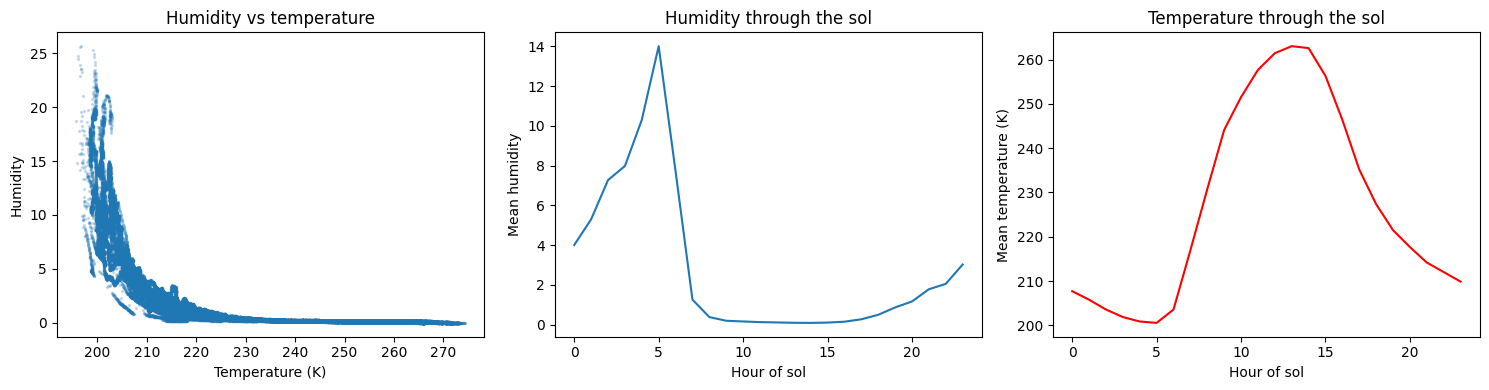

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].scatter(df[T0], df[TARGET], s=2, alpha=0.2)
ax[0].set_xlabel("Temperature (K)")
ax[0].set_ylabel("Humidity")
ax[0].set_title("Humidity vs temperature")

hourly = df.groupby(df["hour"].astype(int))[[TARGET, T0]].mean()
ax[1].plot(hourly.index, hourly[TARGET])
ax[1].set_xlabel("Hour of sol")
ax[1].set_ylabel("Mean humidity")
ax[1].set_title("Humidity through the sol")

ax[2].plot(hourly.index, hourly[T0], color="red")
ax[2].set_xlabel("Hour of sol")
ax[2].set_ylabel("Mean temperature (K)")
ax[2].set_title("Temperature through the sol")

plt.tight_layout()
plt.show()

## Correlation

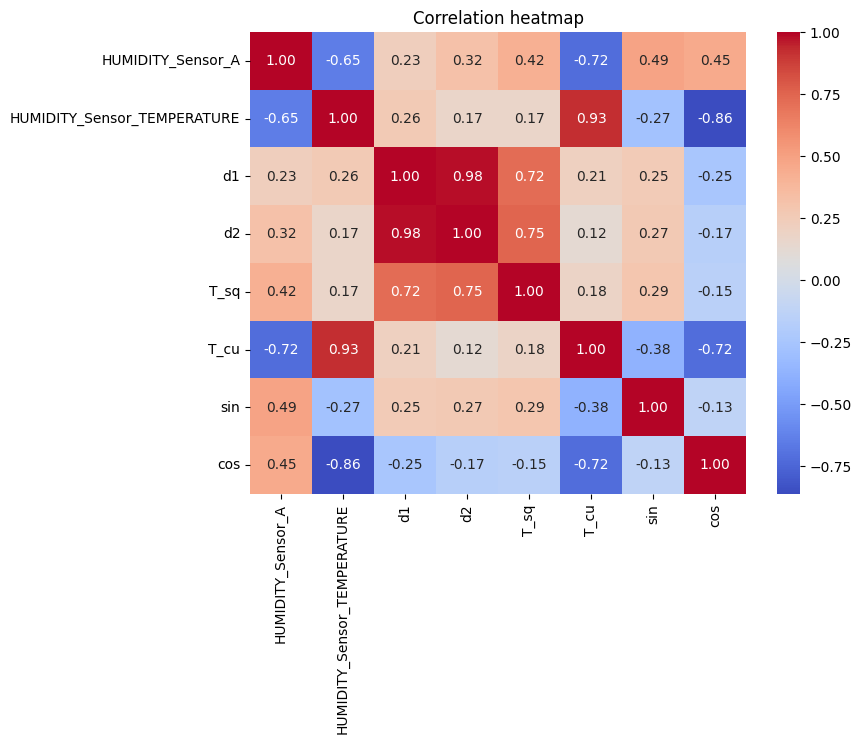

In [12]:
cols = [TARGET] + features
corr = df[cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.show()

## Train / test split
Readings are only one second apart, so neighbouring rows are almost identical. With a normal random split the test rows have near copies in the training set, so a random split can flatter the score. First we check how much that matters here.

In [13]:
X = df[features]
y = np.log1p(df[TARGET])

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
m = LinearRegression().fit(X_tr, y_tr)
p = np.expm1(m.predict(X_te))
print("random split R2:", r2_score(np.expm1(y_te), p))

random split R2: 0.8584955459077607


So we split by sol instead. Whole days (sols 405, 410, 416, 421, 426) go to the test set and the model never sees them in training. In this run the random-split score (0.858) is not higher than the sol-split score (0.871). The two are measured on different test rows, so they are not strictly comparable, and a plain linear model cannot memorise neighbouring rows the way a flexible model could. Splitting by sol is still the fairer test, because it asks whether the model works on a day it has not seen.

In [14]:
test_sols = [405, 410, 416, 421, 426]
is_test = df["sol"].isin(test_sols)

X_train, X_test = X[~is_test], X[is_test]
y_train, y_test = y[~is_test], y[is_test]
actual = df.loc[is_test, TARGET]

print("train rows:", len(X_train), " test rows:", len(X_test))

train rows: 85287  test rows: 18993


## Linear Regression

In [15]:
model = LinearRegression()
model.fit(X_train, y_train)
pred = np.expm1(model.predict(X_test))

print("R2 :", r2_score(actual, pred))
print("MSE:", mean_squared_error(actual, pred))

R2 : 0.8712309427424159
MSE: 0.9530716099111669


Effect of the new features (all on the test sols):

In [16]:
def score(cols, use_log):
    target = np.log1p(df[TARGET]) if use_log else df[TARGET]
    m = LinearRegression().fit(df.loc[~is_test, cols], target[~is_test])
    p = m.predict(df.loc[is_test, cols])
    if use_log:
        p = np.expm1(p)
    return r2_score(actual, p)

raw = [T0, T1, T2, "sin", "cos"]
print("raw sensors             :", score(raw, False))
print("raw sensors + log target:", score(raw, True))
print("all new features + log  :", score(features, True))

raw sensors             : 0.6864170994702099
raw sensors + log target: 0.7919215600180394
all new features + log  : 0.8712309427424159


## Ridge (L2) and Lasso (L1)

In [17]:
models = {
    "Linear": LinearRegression(),
    "Ridge (L2)": Ridge(alpha=1.0),
    "Lasso (L1)": Lasso(alpha=0.001),
}

preds = {}
for name, mdl in models.items():
    mdl.fit(X_train, y_train)
    p = np.expm1(mdl.predict(X_test))
    preds[name] = p
    print(name, " R2 =", round(r2_score(actual, p), 4), " MSE =", round(mean_squared_error(actual, p), 4))

Linear  R2 = 0.8712  MSE = 0.9531
Ridge (L2)  R2 = 0.8713  MSE = 0.9528
Lasso (L1)  R2 = 0.8739  MSE = 0.9336


## Coefficients (theta)

In [18]:
lasso = models["Lasso (L1)"]
theta = pd.DataFrame({"feature": features, "theta": lasso.coef_})
print("intercept:", lasso.intercept_)
theta

intercept: 3.7023764691232586


,feature,theta
0,HUMIDITY_Sensor_TEMPERATURE,-0.014941
1,d1,-0.000000
2,d2,-0.000000
3,T_sq,0.489763
4,T_cu,-0.222142
5,sin,-0.009873
6,cos,0.035404


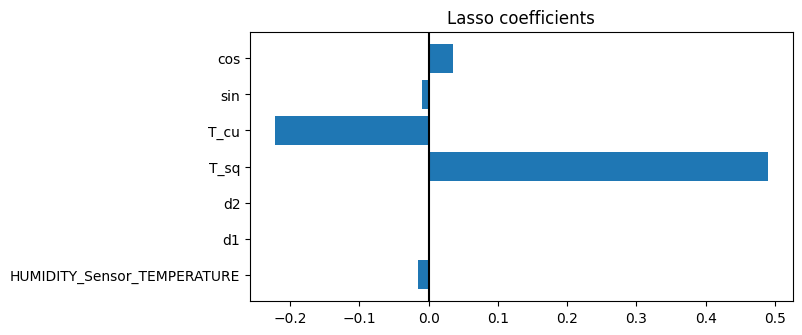

In [19]:
plt.figure(figsize=(7, 3.5))
plt.barh(theta["feature"], theta["theta"])
plt.axvline(0, color="black")
plt.title("Lasso coefficients")
plt.show()

## Results on the test sols

In [20]:
pred = preds["Lasso (L1)"]
print("R2  :", r2_score(actual, pred))
print("MSE :", mean_squared_error(actual, pred))
print("RMSE:", mean_squared_error(actual, pred) ** 0.5)
print("MAE :", np.mean(np.abs(actual.values - pred)))

print()
sols = df.loc[is_test, "sol"].values
for s in test_sols:
    a = actual.values[sols == s]
    p = pred[sols == s]
    print("sol", s, " rows:", len(a), " R2:", round(r2_score(a, p), 3), " RMSE:", round(mean_squared_error(a, p) ** 0.5, 3))

R2  : 0.8738581103712281
MSE : 0.9336268851082983
RMSE: 0.9662436986124662
MAE : 0.4043792139723427

sol 405  rows: 4399  R2: 0.773  RMSE: 1.138
sol 410  rows: 5213  R2: 0.788  RMSE: 0.406
sol 416  rows: 800  R2: -1.08  RMSE: 1.66
sol 421  rows: 5560  R2: 0.973  RMSE: 0.329
sol 426  rows: 3021  R2: 0.86  RMSE: 1.665


Sol 416 has a low R2. It only has about 800 rows and covers just the first 3 hours of the sol, so humidity hardly changes in it and R2 is very sensitive there.  Its RMSE (1.66) is almost the same as sol 426 (1.665), where R2 is 0.86. Sol 416 also has the highest average temperature uncertainty of all sols (0.215), so noisier sensor readings may play a part too.

## Which inputs matter?
We remove one group of inputs at a time, refit Linear Regression and see how much the test R2 drops.

In [21]:
groups = {
    "all inputs": features,
    "without temperature (T, T^2, T^3)": [f for f in features if f not in [T0, "T_sq", "T_cu"]],
    "without T^2 and T^3": [f for f in features if f not in ["T_sq", "T_cu"]],
    "without d1 and d2": [f for f in features if f not in ["d1", "d2"]],
    "without sin and cos": [f for f in features if f not in ["sin", "cos"]],
}

for name, cols in groups.items():
    m = LinearRegression().fit(df.loc[~is_test, cols], y[~is_test])
    p = np.expm1(m.predict(df.loc[is_test, cols]))
    print(name.ljust(34), round(r2_score(actual, p), 4))

all inputs                         0.8712
without temperature (T, T^2, T^3)  0.685
without T^2 and T^3                0.7919
without d1 and d2                  0.8709
without sin and cos                0.8781


## Is the result stable?
So far we used one set of test sols. Here we repeat the split-by-sol 10 times, each time holding out 5 random sols, and look at the spread of R2.

In [22]:
rng = np.random.RandomState(42)
all_sols = sorted(df["sol"].unique())
scores = []

for i in range(10):
    held = rng.choice(all_sols, 5, replace=False)
    mask = df["sol"].isin(held)
    m = Lasso(alpha=0.001).fit(X[~mask], y[~mask])
    p = np.expm1(m.predict(X[mask]))
    scores.append(r2_score(df.loc[mask, TARGET], p))

print([round(v, 3) for v in scores])
print("mean:", round(np.mean(scores), 3), " std:", round(np.std(scores), 3),
      " min:", round(min(scores), 3), " max:", round(max(scores), 3))

[0.826, 0.639, 0.799, 0.957, 0.953, 0.844, 0.857, 0.805, 0.722, 0.786]
mean: 0.819  std: 0.091  min: 0.639  max: 0.957


## Plots

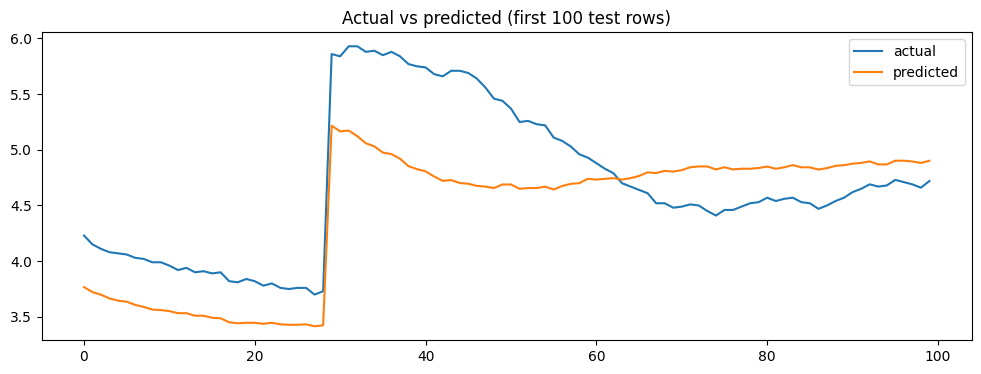

In [23]:
plt.figure(figsize=(12, 4))
plt.plot(actual.values[:100], label="actual")
plt.plot(pred[:100], label="predicted")
plt.legend()
plt.title("Actual vs predicted (first 100 test rows)")
plt.show()

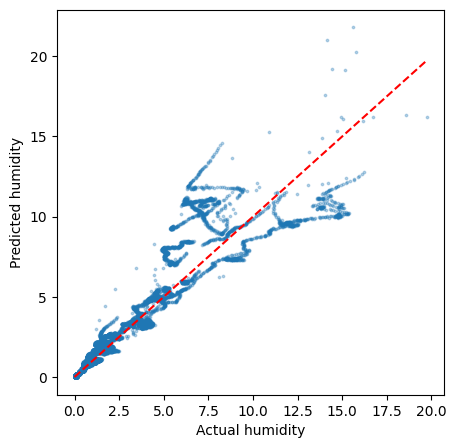

In [24]:
plt.figure(figsize=(5, 5))
plt.scatter(actual, pred, s=3, alpha=0.3)
plt.plot([0, actual.max()], [0, actual.max()], "r--")
plt.xlabel("Actual humidity")
plt.ylabel("Predicted humidity")
plt.show()

## Conclusion
- Missing values, -999 values and sensor spikes were removed before modelling (551 spike rows out of about 104,800).
- On the 5 unseen test sols, Linear Regression gets R2 = 0.871, Ridge 0.871 and Lasso 0.874 (MSE 0.953, 0.953, 0.934). The three are almost the same, so Ridge and Lasso do not help much on this data.
- The new features matter: raw sensors R2 = 0.686, adding the log target 0.792, adding temperature squared and cubed 0.871.
- Temperature is the main input. Removing temperature, T^2 and T^3 drops R2 from 0.871 to 0.685; removing only T^2 and T^3 drops it to 0.792.
- The thermocouple differences (d1, d2) add almost nothing: removing them changes R2 from 0.8712 to 0.8709.
- Time of day (sin, cos) does not help here: removing it raises R2 slightly, from 0.871 to 0.878.
- The 0.874 comes from one choice of 5 test sols. Repeating the split 10 times with random sols gives a mean R2 of 0.819 (std 0.091, range 0.639 to 0.957), so a fair expectation for new sols is about 0.82, give or take 0.09.
- Sol 416 is a short partial sol and has a negative R2 (-1.08) even though its RMSE is similar to sol 426.
- We split by sol so that the model is tested on days it has not seen. Here a random split gave a similar score (0.858), so the split did not change the result much, but it is the safer design with one-second readings.